# 02 · SVM: kernels y regresión (SVR)

In [1]:
# Librerías base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Funciones compartidas del proyecto (métricas, gráficas, rutas) -> archivo churn_utils.py
from churn_utils import *

pd.options.display.max_columns = None
plt.rcParams["figure.dpi"] = 100

from sklearn import svm
from sklearn.svm import SVC, SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report, make_scorer
import time

In [2]:
# Cargar los datos ya preparados por el notebook 00 (mismo train/test para TODOS los modelos)
datos = cargar_datos_modelo()
X_train, X_test = datos["X_train"], datos["X_test"]
y_train, y_test = datos["y_train"], datos["y_test"]

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)
print("Tasa de fuga en train: %.2f%% | en test: %.2f%%" % (100 * y_train.mean(), 100 * y_test.mean()))

Entrenamiento: (8101, 33) | Test: (2026, 33)
Tasa de fuga en train: 16.07% | en test: 16.04%


## 1. SVM por defecto

In [3]:
# Correr SVM: estandarizar + SVC dentro de un Pipeline
svm_estimators = []
svm_estimators.append(("standardize", StandardScaler()))      # Escalar los datos
svm_estimators.append(("svm", svm.SVC(probability=True, random_state=SEMILLA)))

Classifier_SVM = Pipeline(svm_estimators, verbose=False)
Classifier_SVM.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardize', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](33,)","['customer_age','dependent_count','months_on_book',..., 'income_category_Unknown','card_category_Other_card_category', 'card_category_Silver']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,33
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Métricas del modelo: SVM RBF (por defecto)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1655  106]
 [  46  219]]
 Accuracy        : 0.9250
 Sensibilidad    : 0.6738
 Especificidad   : 0.9730
 Precision (VPP) : 0.8264
 VPN             : 0.9398
 F1              : 0.7424
 AUC             : 0.9469
 PR-AUC          : 0.8236


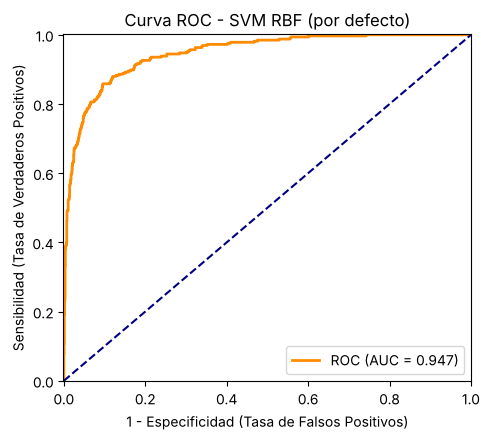

In [4]:
# Predecir con el set de test y calcular métricas
class_threshold = 0.5
y_pred_prob = Classifier_SVM.predict_proba(X_test)[:, 1]
metricas_svm_default = evaluar_modelo("SVM RBF (por defecto)", y_test, y_pred_prob, class_threshold)

* AUC alto, pero la sensibilidad es baja con umbral 0,5.

## 2. Comparación de kernels (validación cruzada)

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
from sklearn.model_selection import cross_val_score

resultados_kernel = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    inicio = time.time()
    modelo = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel))])
    auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    resultados_kernel.append({"kernel": kernel, "AUC CV promedio": auc_cv.mean(), "AUC CV desv.": auc_cv.std(),
                              "segundos": time.time() - inicio})
tabla_kernels = pd.DataFrame(resultados_kernel).sort_values("AUC CV promedio", ascending=False)
tabla_kernels.round(4)

,kernel,AUC CV promedio,AUC CV desv.,segundos
2,rbf,0.9538,0.0060,1.6498
0,linear,0.9327,0.0092,4.1915
1,poly,0.9311,0.0070,1.5079
3,sigmoid,0.8450,0.0136,2.0271


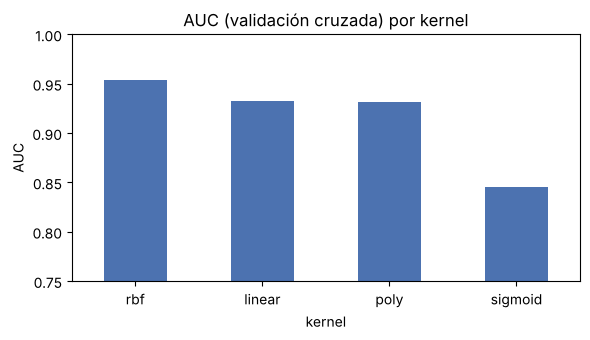

In [6]:
tabla_kernels.set_index("kernel")["AUC CV promedio"].plot(kind="bar", color="#4C72B0", figsize=(6, 3.5), ylim=(0.75, 1))
plt.title("AUC (validación cruzada) por kernel"); plt.ylabel("AUC"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

* El RBF es el mejor; el lineal queda abajo → la relación no es lineal.

### 2.1 Frontera de decisión con 2 variables

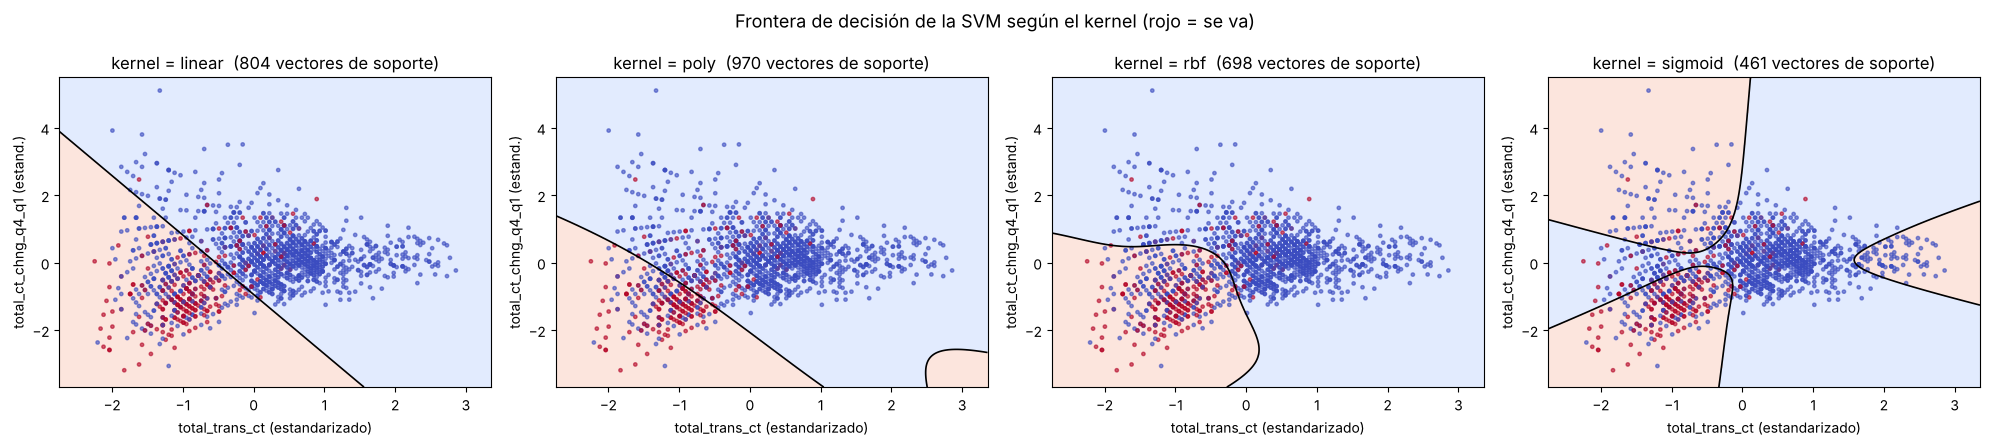

In [7]:
vars_2d = ["total_trans_ct", "total_ct_chng_q4_q1"]
muestra = X_train.sample(1500, random_state=SEMILLA)
X2, y2 = muestra[vars_2d].values, y_train.loc[muestra.index].values
sc2 = StandardScaler().fit(X2); X2s = sc2.transform(X2)

xx, yy = np.meshgrid(np.linspace(X2s[:, 0].min() - .5, X2s[:, 0].max() + .5, 300),
                     np.linspace(X2s[:, 1].min() - .5, min(X2s[:, 1].max(), 5) + .5, 300))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, kernel in zip(axes, ["linear", "poly", "rbf", "sigmoid"]):
    m = SVC(kernel=kernel, C=1, class_weight="balanced").fit(X2s, y2)
    Z = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.25, cmap="coolwarm")
    ax.contour(xx, yy, Z, levels=[0], colors="k", linewidths=1.2)
    ax.scatter(X2s[:, 0], X2s[:, 1], c=y2, cmap="coolwarm", s=6, alpha=0.6)
    ax.set_ylim(yy.min(), yy.max())
    ax.set_title(f"kernel = {kernel}  ({len(m.support_)} vectores de soporte)")
    ax.set_xlabel("total_trans_ct (estandarizado)"); ax.set_ylabel("total_ct_chng_q4_q1 (estand.)")
plt.suptitle("Frontera de decisión de la SVM según el kernel (rojo = se va)", fontsize=13)
plt.tight_layout(); plt.savefig(f"{FIGURAS_DIR}/svm_kernels_2d.png", bbox_inches="tight"); plt.show()

## 3. GridSearchCV para el kernel RBF
Se usa `scoring="roc_auc"` para optimizar el AUC con probabilidades.

In [8]:
steps = [("scaler", StandardScaler()), ("SVM", SVC(kernel="rbf"))]
pipeline = Pipeline(steps)

# Definir la variación de los hiperparámetros
param_grid = {"SVM__C": [0.1, 1, 10, 30, 100],
              "SVM__gamma": ["scale", 0.01, 0.03, 0.1],
              "SVM__class_weight": [None, "balanced"]}

grid = GridSearchCV(pipeline, param_grid=param_grid, cv=cv, scoring="roc_auc",
                    refit=True, verbose=1, return_train_score=True, n_jobs=-1)
inicio = time.time()
grid_search_svm = grid.fit(X_train, y_train)
print("Tiempo: %.1f s" % (time.time() - inicio))
print("Mejores hiperparámetros:", grid_search_svm.best_params_)
print("Mejor AUC en validación cruzada: %.4f" % grid_search_svm.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


Tiempo: 176.1 s
Mejores hiperparámetros: {'SVM__C': 10, 'SVM__class_weight': None, 'SVM__gamma': 0.01}
Mejor AUC en validación cruzada: 0.9579


In [9]:
# Ver los resultados de la búsqueda: AUC de train vs validación (para detectar sobreajuste)
res = pd.DataFrame(grid_search_svm.cv_results_)
cols = ["param_SVM__C", "param_SVM__gamma", "param_SVM__class_weight", "mean_train_score", "mean_test_score", "rank_test_score"]
res[cols].sort_values("rank_test_score").head(10).round(4)

,param_SVM__C,param_SVM__gamma,param_SVM__class_weight,mean_train_score,mean_test_score,rank_test_score
17,10.0,0.01,NaN,0.9804,0.9579,1
21,10.0,0.01,balanced,0.9848,0.9574,2
25,30.0,0.01,NaN,0.9886,0.9574,3
14,1.0,0.03,balanced,0.9852,0.9561,4
12,1.0,scale,balanced,0.9853,0.9561,5
29,30.0,0.01,balanced,0.9911,0.9557,6
33,100.0,0.01,NaN,0.9952,0.9544,7
10,1.0,0.03,NaN,0.9784,0.9538,8
8,1.0,scale,NaN,0.9785,0.9538,9
13,1.0,0.01,balanced,0.9672,0.9528,10


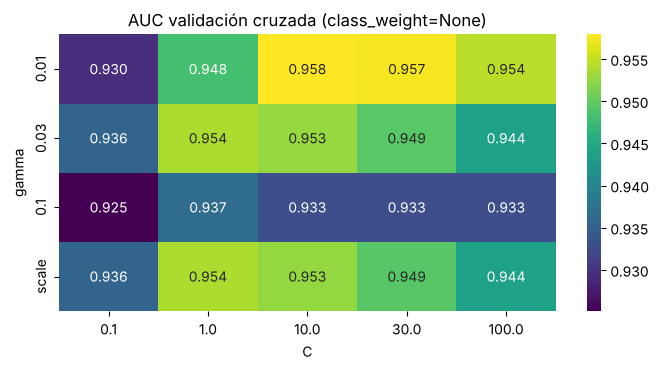

In [10]:
# Mapa de calor: AUC de validación según C y gamma (con el mejor class_weight)
mejor_cw = grid_search_svm.best_params_["SVM__class_weight"]
res["cw"] = res["params"].apply(lambda p: str(p["SVM__class_weight"]))
res["gamma"] = res["params"].apply(lambda p: str(p["SVM__gamma"]))
res["C"] = res["params"].apply(lambda p: p["SVM__C"])
sub = res[res["cw"] == str(mejor_cw)]
pivote = sub.pivot_table(index="gamma", columns="C", values="mean_test_score", aggfunc="first")
import seaborn as sns
plt.figure(figsize=(7, 3.8))
sns.heatmap(pivote, annot=True, fmt=".3f", cmap="viridis")
plt.title(f"AUC validación cruzada (class_weight={mejor_cw})"); plt.xlabel("C"); plt.ylabel("gamma"); plt.tight_layout(); plt.show()

* C y gamma muy altos sobreajustan; muy bajos subajustan.

Métricas del modelo: SVM RBF (ajustado)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1660  107]
 [  41  218]]
 Accuracy        : 0.9269
 Sensibilidad    : 0.6708
 Especificidad   : 0.9759
 Precision (VPP) : 0.8417
 VPN             : 0.9394
 F1              : 0.7466
 AUC             : 0.9543
 PR-AUC          : 0.8302


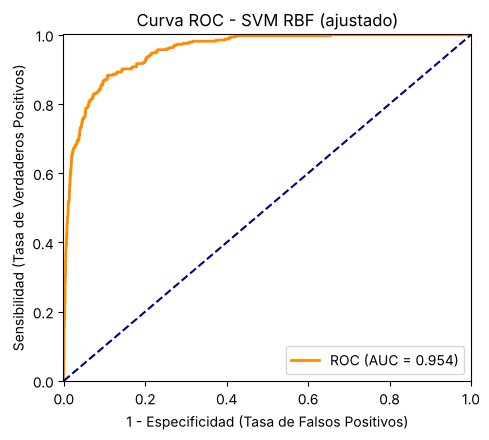

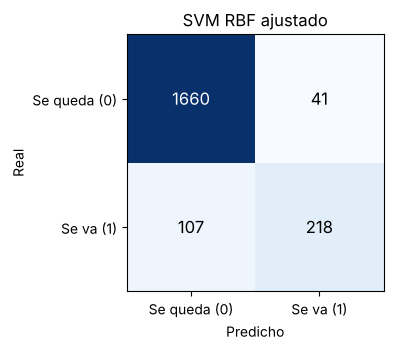

In [11]:
# Reentrenar el mejor modelo con probability=True para obtener probabilidades y evaluar en TEST
mejores = {k.replace("SVM__", ""): v for k, v in grid_search_svm.best_params_.items()}
SVM_final = Pipeline([("scaler", StandardScaler()),
                      ("SVM", SVC(kernel="rbf", probability=True, random_state=SEMILLA, **mejores))])
SVM_final.fit(X_train, y_train)

y_pred_prob_svm = SVM_final.predict_proba(X_test)[:, 1]
metricas_svm = evaluar_modelo("SVM RBF (ajustado)", y_test, y_pred_prob_svm)
plot_confusion(y_test, np.where(y_pred_prob_svm > 0.5, 1, 0), "SVM RBF ajustado")

In [12]:
print(classification_report(y_test, np.where(y_pred_prob_svm > 0.5, 1, 0), target_names=["Se queda", "Se va"]))
guardar_resultados("SVM RBF", y_test, y_pred_prob_svm, metricas_svm, grid_search_svm.best_params_)

              precision    recall  f1-score   support

    Se queda       0.94      0.98      0.96      1701
       Se va       0.84      0.67      0.75       325

    accuracy                           0.93      2026
   macro avg       0.89      0.82      0.85      2026
weighted avg       0.92      0.93      0.92      2026

Resultados guardados en: resultados/SVM_RBF.pkl


### 3.1 Kernel polinomial ajustado

In [13]:
grid_poly = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("SVM", SVC(kernel="poly"))]),
                         param_grid={"SVM__degree": [2, 3], "SVM__C": [0.1, 1, 10], "SVM__class_weight": [None, "balanced"]},
                         cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
print("Mejores hiperparámetros poly:", grid_poly.best_params_, "| AUC CV: %.4f" % grid_poly.best_score_)

y_pred_prob_poly = grid_poly.best_estimator_.decision_function(X_test)
# decision_function no es probabilidad: la convertimos a [0,1] con una sigmoide solo para poder usar umbral 0.5
y_pred_prob_poly = 1 / (1 + np.exp(-y_pred_prob_poly))
metricas_poly = evaluar_modelo("SVM Polinomial", y_test, y_pred_prob_poly, graficar=False)
guardar_resultados("SVM Polinomial", y_test, y_pred_prob_poly, metricas_poly, grid_poly.best_params_)

Mejores hiperparámetros poly: {'SVM__C': 1, 'SVM__class_weight': None, 'SVM__degree': 3} | AUC CV: 0.9311
Métricas del modelo: SVM Polinomial  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1671  159]
 [  30  166]]
 Accuracy        : 0.9067
 Sensibilidad    : 0.5108
 Especificidad   : 0.9824
 Precision (VPP) : 0.8469
 VPN             : 0.9131
 F1              : 0.6372
 AUC             : 0.9270
 PR-AUC          : 0.7854
Resultados guardados en: resultados/SVM_Polinomial.pkl


## 4. SVR
4.1 SVR como score de riesgo · 4.2 SVR para predecir el valor transado.

In [14]:
# 4.1 SVR como score de riesgo de fuga
# OJO: scoring="roc_auc" no funciona con regresores (no tienen predict_proba ni decision_function).
# Aquí SÍ sirve make_scorer(roc_auc_score): le pasa la predicción continua de la SVR, que es justo el score que queremos evaluar.
score_auc_regresor = make_scorer(roc_auc_score)
grid_svr = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("SVR", SVR(kernel="rbf"))]),
                        param_grid={"SVR__C": [0.3, 1, 3], "SVR__epsilon": [0.05, 0.1, 0.2]},
                        cv=cv, scoring=score_auc_regresor, n_jobs=-1).fit(X_train, y_train)
print("Mejores hiperparámetros SVR:", grid_svr.best_params_, "| AUC CV: %.4f" % grid_svr.best_score_)

score_svr = grid_svr.best_estimator_.predict(X_test)
print("Rango del score SVR: [%.2f, %.2f]  -> no es una probabilidad" % (score_svr.min(), score_svr.max()))
# Lo llevamos a [0,1] con min-max usando el rango observado en TRAIN (sin mirar test) y recortamos lo que se salga
score_train = grid_svr.best_estimator_.predict(X_train)
y_pred_prob_svr = np.clip((score_svr - score_train.min()) / (score_train.max() - score_train.min()), 0, 1)
metricas_svr = evaluar_modelo("SVR (score de riesgo)", y_test, y_pred_prob_svr, graficar=False)
guardar_resultados("SVR score", y_test, y_pred_prob_svr, metricas_svr, grid_svr.best_params_)

Mejores hiperparámetros SVR: {'SVR__C': 0.3, 'SVR__epsilon': 0.2} | AUC CV: 0.9542


Rango del score SVR: [-0.33, 1.27]  -> no es una probabilidad


Métricas del modelo: SVR (score de riesgo)  (umbral = 0.5)

Matriz de confusión (formato clase: filas = predicho, columnas = real):
[[1690  195]
 [  11  130]]
 Accuracy        : 0.8983
 Sensibilidad    : 0.4000
 Especificidad   : 0.9935
 Precision (VPP) : 0.9220
 VPN             : 0.8966
 F1              : 0.5579
 AUC             : 0.9465
 PR-AUC          : 0.8247
Resultados guardados en: resultados/SVR_score.pkl


R²  : 0.702
MAE : 1030
RMSE: 1793


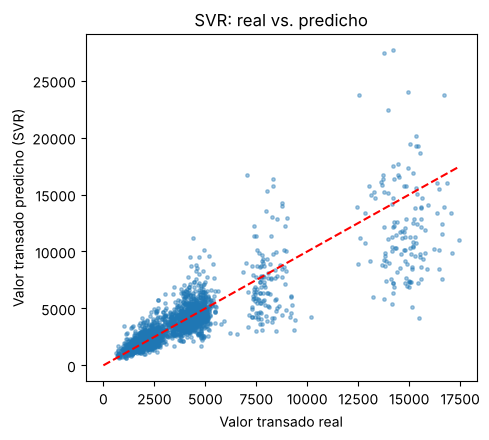

In [15]:
# 4.2 SVR para regresión: predecir el valor total transado (total_trans_amt)
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

Xr_train = X_train.drop(columns=["total_trans_amt", "ticket_promedio"])   # quitamos variables que contienen la respuesta
Xr_test = X_test.drop(columns=["total_trans_amt", "ticket_promedio"])
yr_train, yr_test = np.log1p(X_train["total_trans_amt"]), np.log1p(X_test["total_trans_amt"])  # log para reducir asimetría

svr_reg = Pipeline([("scaler", StandardScaler()), ("SVR", SVR(kernel="rbf", C=10, epsilon=0.05))]).fit(Xr_train, yr_train)
pred = np.expm1(svr_reg.predict(Xr_test)); real = np.expm1(yr_test)

print("R²  : %.3f" % r2_score(real, pred))
print("MAE : %.0f" % mean_absolute_error(real, pred))
print("RMSE: %.0f" % np.sqrt(mean_squared_error(real, pred)))

plt.figure(figsize=(5, 4.5))
plt.scatter(real, pred, s=6, alpha=0.4); lim = [0, real.max()]
plt.plot(lim, lim, "r--"); plt.xlabel("Valor transado real"); plt.ylabel("Valor transado predicho (SVR)")
plt.title("SVR: real vs. predicho"); plt.tight_layout(); plt.show()

* La SVR explica ~70% de la variación del valor transado (R² ≈ 0,70).

## Resumen SVM
* Mejor kernel: RBF (C = 10, gamma = 0,01), AUC test 0,954.
* SVR como score: AUC 0,946.
* Poco interpretable y probabilidades no nativas.